# Marketing Performance Case Study: Where Should the Next Dollar Go?

**Client (fictional):** Ridgeline Supply Co., a direct-to-consumer outdoor gear brand spending about $4.8M a year across five channels.

**The question leadership asked:** *Which channels are actually driving revenue, which customers are worth keeping, and how should we split next year's budget?*

This notebook answers it end to end on a synthetic dataset built to behave like real DTC data (carryover, diminishing returns, seasonality, noisy customers). Because the data is simulated, the true channel effects are known, so the media mix model can be checked against ground truth, something you never get with real data.

**What's inside**
1. Data generation (weekly spend + revenue, 20,000 customers with order histories)
2. Media mix model with adstock and saturation, validated against the true ROAS
3. Budget reallocation at the same total spend
4. RFM segmentation
5. 12-month customer lifetime value by acquisition channel
6. Repeat-purchase model for retention targeting
7. Recommendations

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import least_squares, minimize
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

rng=np.random.default_rng(42)
INK,INK2,GRID,SURF='#0b0b0b','#52514e','#e4e3df','#fcfcfb'
PAL=['#2a78d6','#eb6834','#1baf7a','#eda100','#e87ba4','#008300','#6250d6']
plt.rcParams.update({'figure.facecolor':SURF,'axes.facecolor':SURF,'axes.edgecolor':GRID,'axes.labelcolor':INK2,
    'xtick.color':INK2,'ytick.color':INK2,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,
    'grid.color':GRID,'grid.linewidth':0.8,'axes.axisbelow':True,'font.family':'DejaVu Sans','font.size':12,
    'axes.titlesize':16,'axes.titleweight':'bold','axes.titlecolor':INK,'axes.titlelocation':'left','savefig.dpi':200})
def save(fig,name): fig.savefig(f'figures/{name}.png',bbox_inches='tight',facecolor=SURF)

## 1. Simulate the data
Each channel gets a true carryover rate (adstock), a saturation point, and an effect size. Revenue is a baseline with trend and seasonality plus each channel's contribution plus noise.

In [2]:
W=156
weeks=pd.date_range('2023-01-08',periods=W,freq='W')
channels=['Paid Search','Paid Social','CTV / Video','Affiliate','Email']
true={'Paid Search':dict(decay=0.15,half=60e3,beta=210e3),
      'Paid Social':dict(decay=0.45,half=45e3,beta=150e3),
      'CTV / Video':dict(decay=0.70,half=55e3,beta=120e3),
      'Affiliate':dict(decay=0.10,half=12e3,beta=40e3),
      'Email':dict(decay=0.30,half=3e3,beta=55e3)}
base_spend={'Paid Search':22e3,'Paid Social':30e3,'CTV / Video':24e3,'Affiliate':6e3,'Email':1.2e3}
season=1+0.1*np.sin(2*np.pi*(np.arange(W)-10)/52)+0.15*np.isin(weeks.month,[11,12])
spend=pd.DataFrame({c:base_spend[c]*season*rng.lognormal(0,0.45,W) for c in channels},index=weeks)
#flighting: ctv runs in bursts
spend['CTV / Video']*=np.where((np.arange(W)//6)%2==0,1.6,0.35)

def adstock(x,d):
    out=np.zeros_like(x,dtype=float); carry=0
    for i,v in enumerate(x): carry=v+d*carry; out[i]=carry
    return out
def hill(x,half): return x/(x+half)

contrib_true=pd.DataFrame({c:true[c]['beta']*hill(adstock(spend[c].values,true[c]['decay'])*(1-true[c]['decay']),true[c]['half']) for c in channels},index=weeks)
baseline=180e3*(1+0.002*np.arange(W))*(1+0.15*np.sin(2*np.pi*(np.arange(W)-10)/52)+0.25*np.isin(weeks.month,[11,12]))
revenue=baseline+contrib_true.sum(axis=1)+rng.normal(0,8e3,W)
mmm=spend.assign(Revenue=revenue)
mmm.to_csv('data/weekly_spend_revenue.csv')
print(f"annual spend ${spend.sum().sum()/3/1e6:.2f}M | annual revenue ${revenue.sum()/3/1e6:.1f}M")
mmm.head()

annual spend $4.76M | annual revenue $21.0M


,Paid Search,Paid Social,CTV / Video,Affiliate,Email,Revenue
2023-01-08,22873.958925,28836.872856,76299.162039,8946.750960,1344.694498,309293.323513
2023-01-15,12557.723432,42551.556943,42644.174013,3547.009133,860.324431,318969.433426
2023-01-22,28300.019973,21990.958272,51150.340952,6438.819989,915.029779,364611.117033
2023-01-29,31077.870969,16283.822536,31087.318672,4621.751328,2049.734332,362826.291402
2023-02-05,8537.458723,18142.941922,36943.504797,4929.228642,701.485258,315020.190887


## 2. Media mix model
Each channel's spend goes through geometric adstock (carryover) and a Hill saturation curve, and all parameters are fit jointly with bounded nonlinear least squares. Trend and seasonality terms absorb the baseline.

In [3]:
t=np.arange(W); X_base=np.column_stack([np.ones(W),t/W,np.sin(2*np.pi*(t-10)/52),np.cos(2*np.pi*(t-10)/52),np.isin(weeks.month,[11,12]).astype(float)])
nb=X_base.shape[1]
def unpack(p):
    b=p[:nb]; rest=p[nb:].reshape(len(channels),3); return b,rest
def predict(p,S=spend):
    b,rest=unpack(p); y=X_base@b*1e5
    parts={}
    for i,c in enumerate(channels):
        d,h,beta=rest[i]; parts[c]=beta*1e5*hill(adstock(S[c].values,d)*(1-d),h*1e4)
    return y+sum(parts.values()),parts
def resid(p): return (predict(p)[0]-revenue)/1e4
p0=np.r_[[1.8,0,0,0,0],np.tile([0.3,3,1],len(channels))]
lo=np.r_[[-np.inf]*nb,np.tile([0.0,0.1,0],len(channels))]; hi=np.r_[[np.inf]*nb,np.tile([0.9,30,10],len(channels))]
best=None
for s in range(20):
    start=p0.copy(); start[nb:]=np.column_stack([rng.uniform(.05,.8,5),rng.uniform(.3,8,5),rng.uniform(.2,3,5)]).ravel()
    r=least_squares(resid,start,bounds=(lo,hi))
    if best is None or r.cost<best.cost: best=r
p=best.x; fit,parts=predict(p)
r2=1-((revenue-fit)**2).sum()/((revenue-revenue.mean())**2).sum()
mape=np.mean(np.abs(revenue-fit)/revenue)
roas=pd.DataFrame({'Estimated ROAS':{c:parts[c].sum()/spend[c].sum() for c in channels},
                   'True ROAS':{c:contrib_true[c].sum()/spend[c].sum() for c in channels},
                   'Estimated decay':{c:unpack(p)[1][i][0] for i,c in enumerate(channels)},
                   'True decay':{c:true[c]['decay'] for c in channels}}).round(2)
print(f"in-sample R2 {r2:.3f} | MAPE {mape:.1%}"); roas

in-sample R2 0.962 | MAPE 1.5%


,Estimated ROAS,True ROAS,Estimated decay,True decay
Paid Search,2.28,2.43,0.09,0.15
Paid Social,1.45,1.84,0.47,0.45
CTV / Video,1.60,1.44,0.68,0.70
Affiliate,1.96,2.07,0.11,0.10
Email,10.83,12.29,0.28,0.30


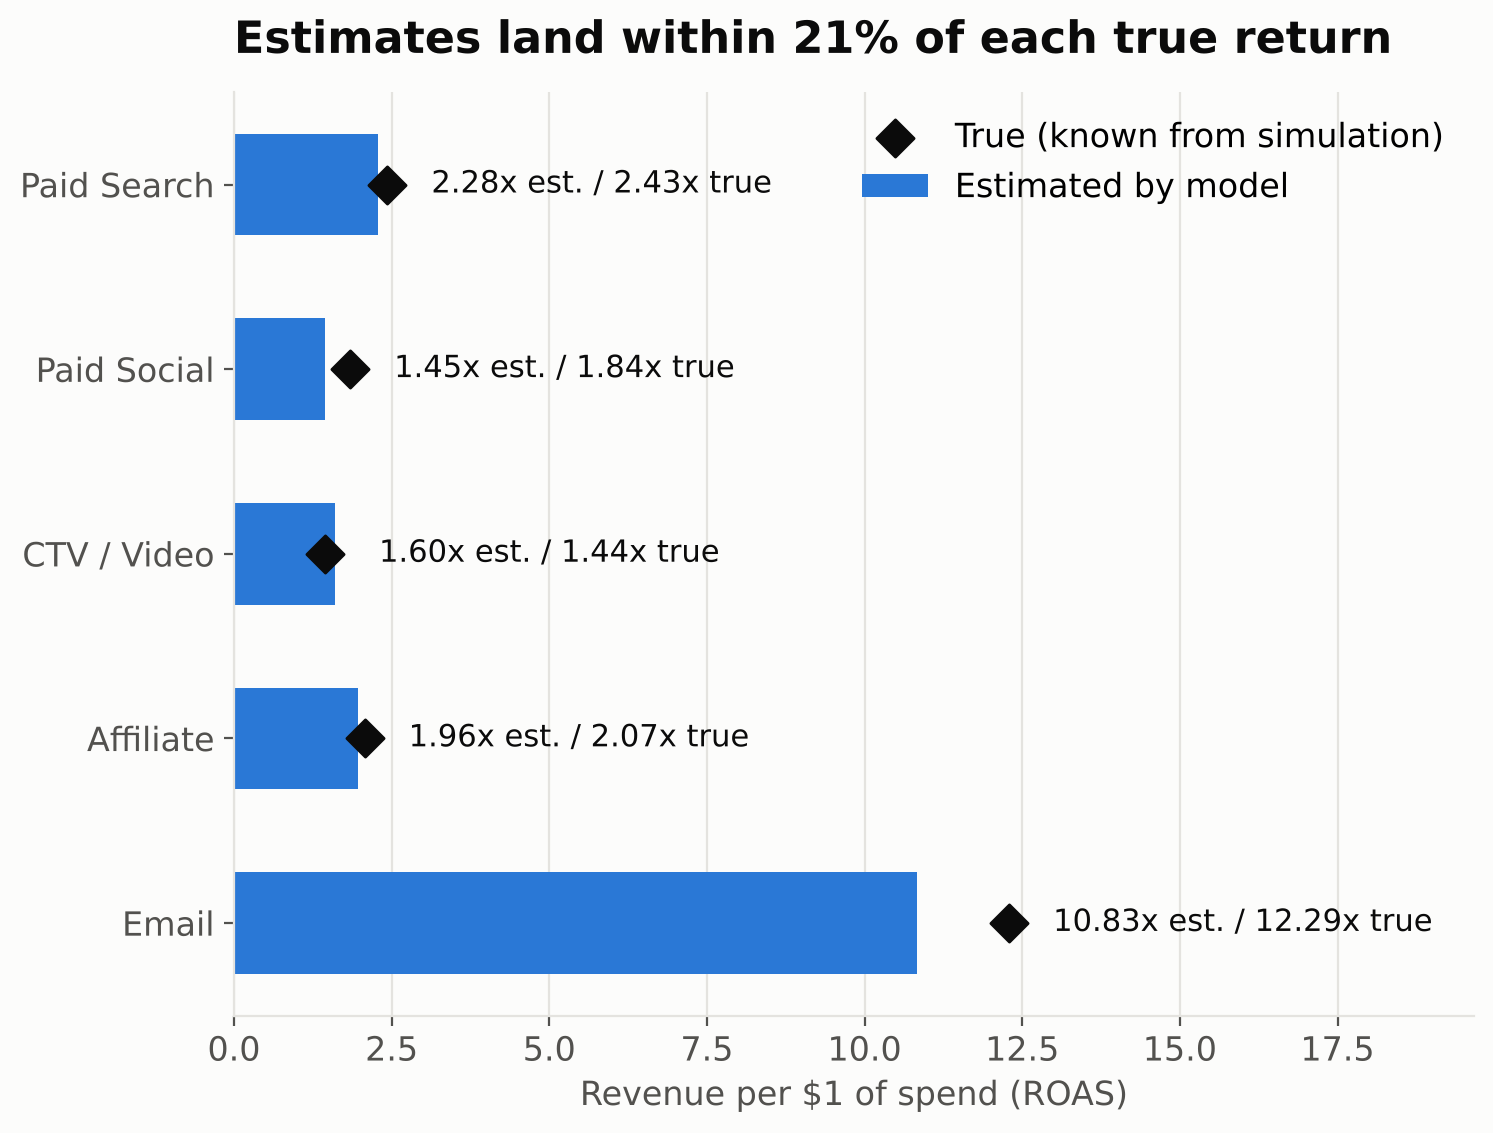

In [4]:
fig,ax=plt.subplots(figsize=(8,6))
y=np.arange(len(channels))[::-1]
ax.barh(y,roas['Estimated ROAS'],height=0.55,color=PAL[0],label='Estimated by model')
ax.scatter(roas['True ROAS'],y,s=90,color=INK,zorder=3,marker='D',label='True (known from simulation)')
for yi,(v,tv) in zip(y,zip(roas['Estimated ROAS'],roas['True ROAS'])): ax.text(max(v,tv)+0.7,yi,f'{v:.2f}x est. / {tv:.2f}x true',va='center',color=INK,fontsize=11)
ax.set_xlim(0,roas[['Estimated ROAS','True ROAS']].max().max()*1.6)
ax.set_yticks(y,channels); ax.grid(axis='y',visible=False)
ax.set_xlabel('Revenue per $1 of spend (ROAS)')
err=(roas['Estimated ROAS']/roas['True ROAS']-1).abs().max(); ax.set_title(f'Estimates land within {err:.0%} of each true return',pad=14)
ax.legend(loc='upper right',frameon=False); save(fig,'01_mmm_roas_vs_truth'); plt.show()

## 3. Response curves and budget reallocation
Average ROAS says where money worked *on average*. The budget decision needs the *marginal* return, the slope of each response curve at current spend. The optimizer finds the split that maximizes steady-state revenue at the **same total budget**, with each channel kept within 50% to 200% of today's spend so the recommendation is realistic.

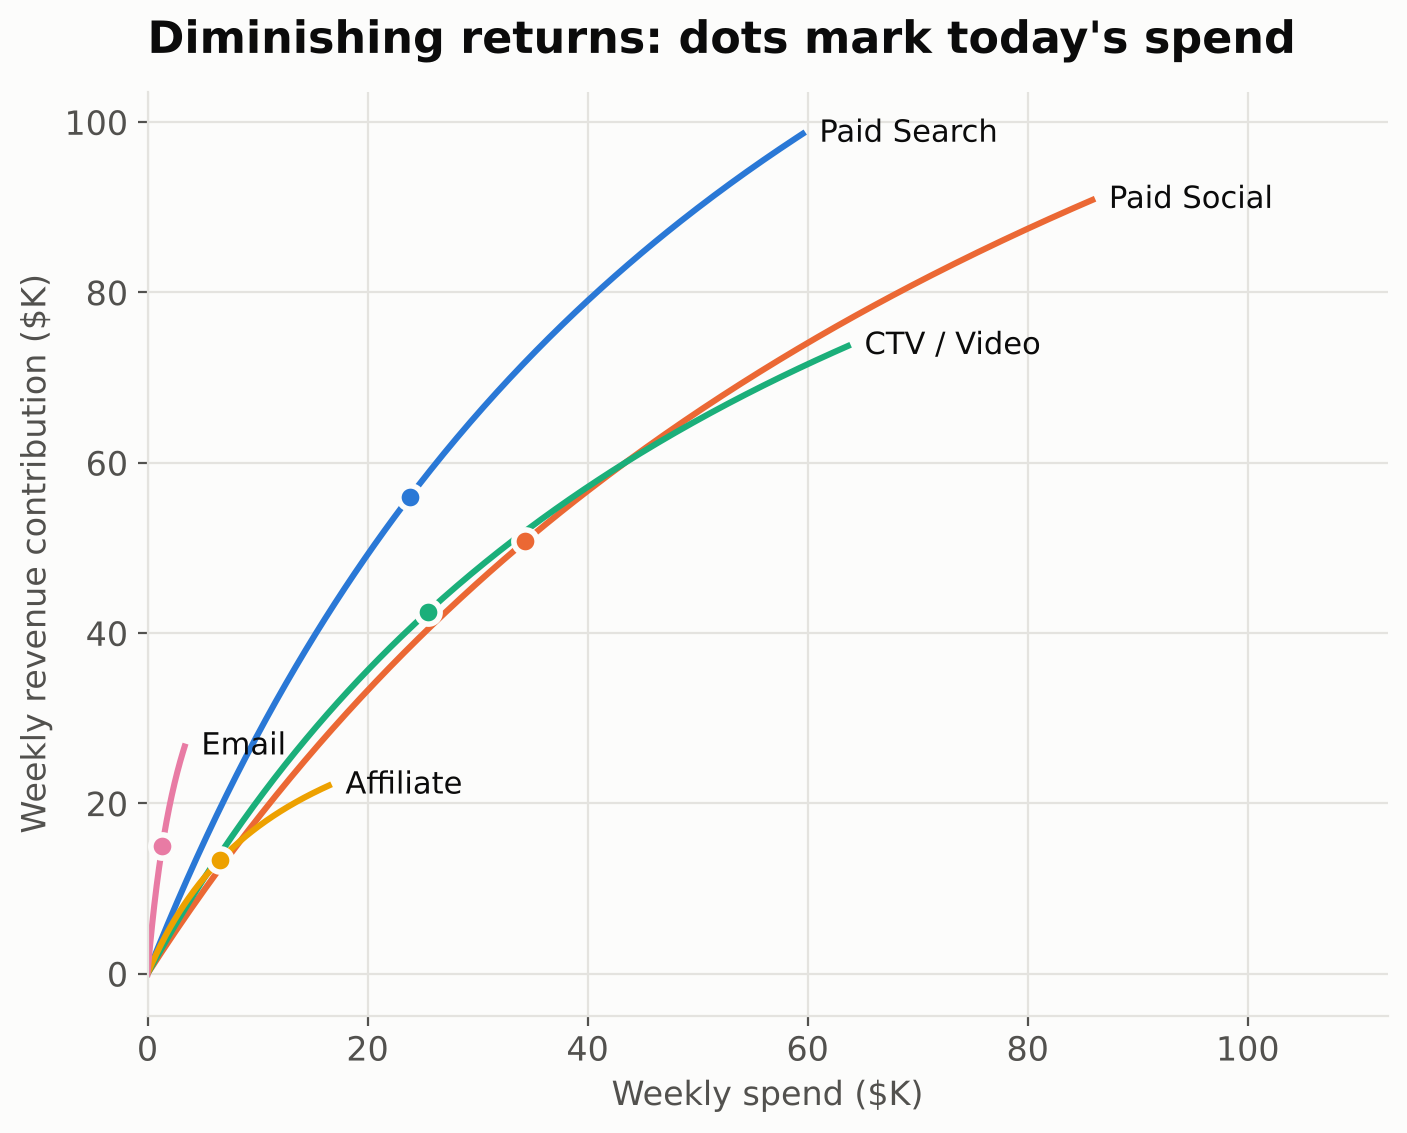

media-driven revenue lift at same budget: model 5.9% | checked against true curves 6.2%
annualized: +$549K revenue


,Current,Optimized,Change
Paid Search,23819.14,36366.07,0.53
Paid Social,34347.37,23839.96,-0.31
CTV / Video,25460.53,21705.21,-0.15
Affiliate,6591.02,6957.06,0.06
Email,1349.75,2699.50,1.00


In [5]:
b,rest=unpack(p)
def weekly_resp(c,s):
    i=channels.index(c); d,h,beta=rest[i]; return beta*1e5*hill(s,h*1e4)
cur=spend.mean()
fig,ax=plt.subplots(figsize=(8,6))
for i,c in enumerate(channels):
    grid=np.linspace(0,cur[c]*2.5,200); ax.plot(grid/1e3,weekly_resp(c,grid)/1e3,color=PAL[i],lw=2.2)
    ax.scatter(cur[c]/1e3,weekly_resp(c,cur[c])/1e3,color=PAL[i],s=70,zorder=3,edgecolor=SURF,linewidth=2)
    ax.annotate(c,(grid[-1]/1e3,weekly_resp(c,grid[-1])/1e3),xytext=(6,0),textcoords='offset points',va='center',color=INK,fontsize=11)
ax.set_xlabel('Weekly spend ($K)'); ax.set_ylabel('Weekly revenue contribution ($K)')
ax.set_title('Diminishing returns: dots mark today\'s spend',pad=14); ax.set_xlim(0,ax.get_xlim()[1]*1.25)
save(fig,'02_response_curves'); plt.show()

total=cur.sum()
def neg_rev(x): return -sum(weekly_resp(c,x[i]) for i,c in enumerate(channels))
bounds=[(cur[c]*0.5,cur[c]*2.0) for c in channels]
opt=minimize(neg_rev,cur.values,bounds=bounds,constraints=[{'type':'eq','fun':lambda x:x.sum()-total}],method='SLSQP')
alloc=pd.DataFrame({'Current':cur,'Optimized':opt.x},index=channels)
alloc['Change']=alloc['Optimized']/alloc['Current']-1
lift=(-opt.fun)/(-neg_rev(cur.values))-1
true_cur=sum(true[c]['beta']*hill(cur[c],true[c]['half']) for c in channels)
true_opt=sum(true[c]['beta']*hill(opt.x[i],true[c]['half']) for i,c in enumerate(channels))
print(f"media-driven revenue lift at same budget: model {lift:.1%} | checked against true curves {true_opt/true_cur-1:.1%}")
print(f"annualized: +${(-opt.fun+neg_rev(cur.values))*52/1e3:,.0f}K revenue")
alloc.round(2)

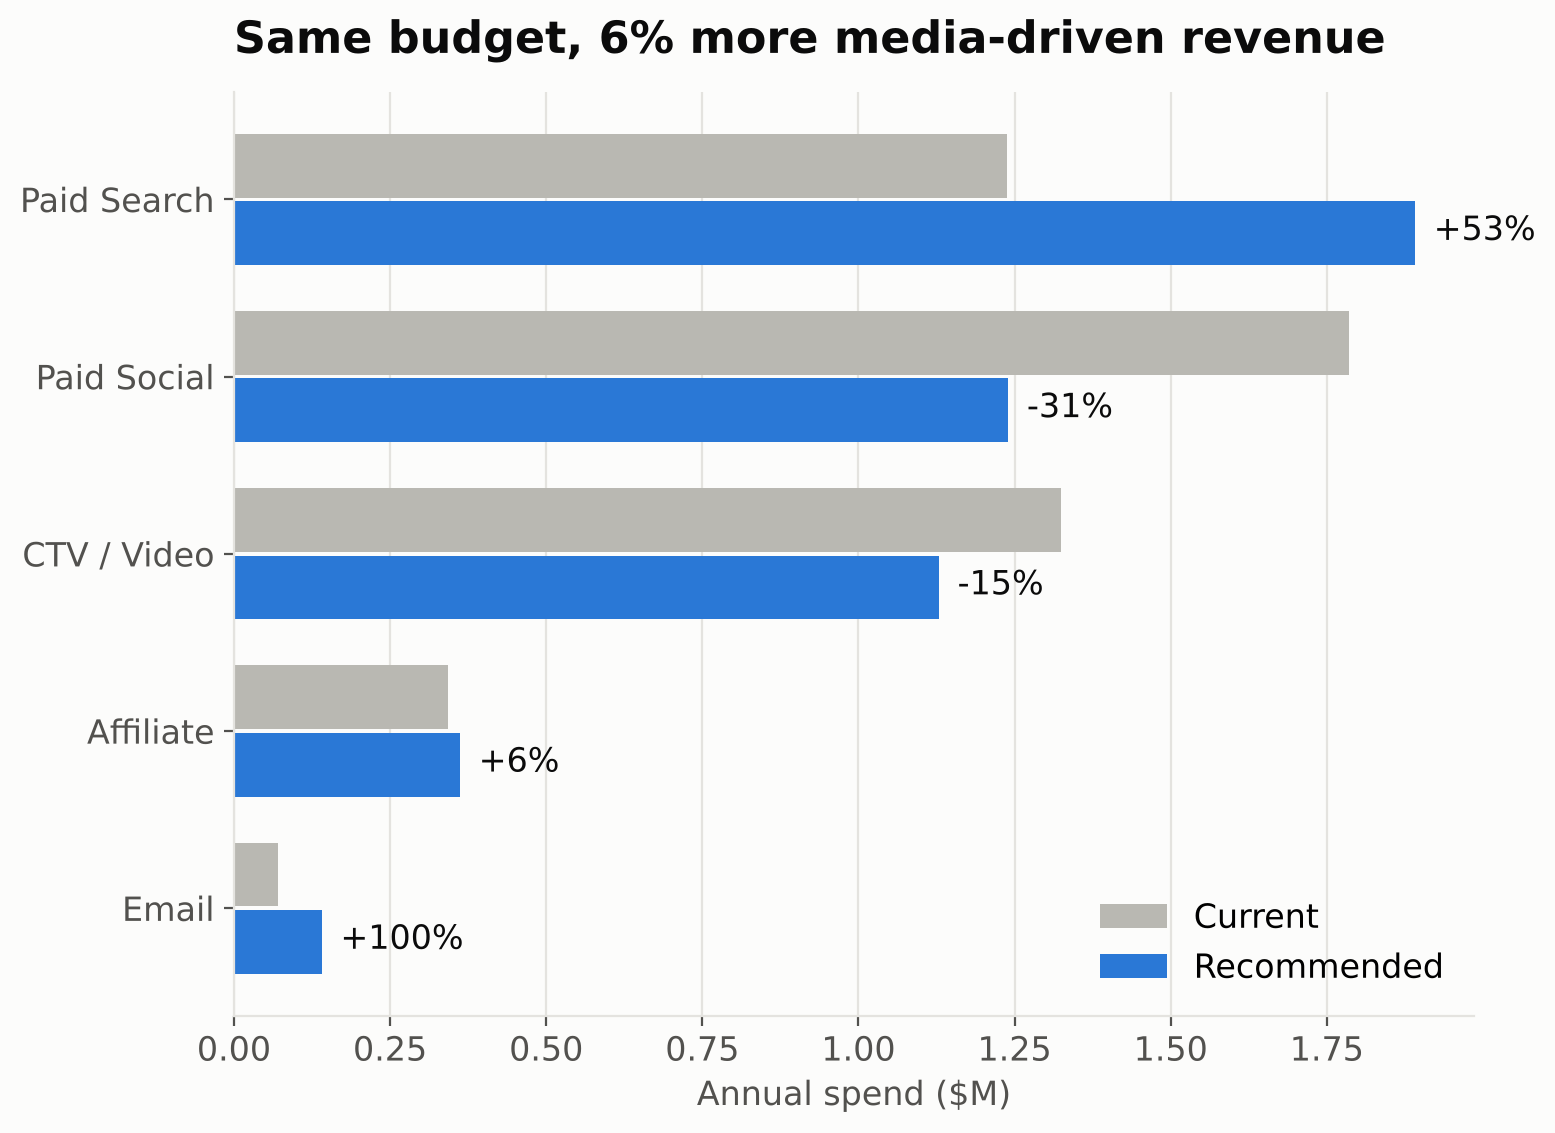

In [6]:
fig,ax=plt.subplots(figsize=(8,6))
y=np.arange(len(channels))[::-1]; h=0.36
ax.barh(y+h/2+0.01,alloc['Current']*52/1e6,height=h,color='#b9b8b2',label='Current')
ax.barh(y-h/2-0.01,alloc['Optimized']*52/1e6,height=h,color=PAL[0],label='Recommended')
for yi,(v,chg) in zip(y,zip(alloc['Optimized']*52/1e6,alloc['Change'])):
    ax.text(v+0.03,yi-h/2,f'{chg:+.0%}',va='center',color=INK,fontsize=12)
ax.set_yticks(y,channels); ax.grid(axis='y',visible=False); ax.set_xlabel('Annual spend ($M)')
ax.set_title(f'Same budget, {lift:.0%} more media-driven revenue',pad=14); ax.legend(frameon=False,loc='lower right')
save(fig,'03_budget_reallocation'); plt.show()

## 4. Customer data: RFM segmentation
20,000 customers, each acquired through one channel, with a purchase rate and a dropout risk that vary by person and by channel. The analysis snapshot is taken at month 18; the following 6 months are held out for the CLV check and the repeat-purchase model.

In [7]:
N=20000
acq=rng.choice(channels,N,p=[.34,.27,.14,.13,.12])
rate_mult={'Paid Search':1.0,'Paid Social':0.75,'CTV / Video':0.9,'Affiliate':0.6,'Email':1.5}
aov_mult={'Paid Search':1.0,'Paid Social':0.85,'CTV / Video':1.15,'Affiliate':0.8,'Email':1.05}
lam=rng.gamma(0.9,1/0.9,N)*np.vectorize(rate_mult.get)(acq)*2.6/365   #orders per day
churn_hz=rng.beta(1.2,12,N)/60*np.where(acq=='Affiliate',1.6,1)        #daily dropout hazard
first=rng.integers(0,540,N); aov=rng.lognormal(np.log(85),0.35,N)*np.vectorize(aov_mult.get)(acq)
rows=[]
for i in range(N):
    d=first[i]; alive=True
    while d<730 and alive:
        rows.append((i,d,max(15,rng.normal(aov[i],aov[i]*0.25))))
        gap=rng.exponential(1/lam[i]); dead=rng.exponential(1/churn_hz[i])
        if dead<gap: alive=False
        d+=int(np.ceil(gap))
orders=pd.DataFrame(rows,columns=['customer_id','day','amount'])
orders['date']=pd.Timestamp('2024-01-01')+pd.to_timedelta(orders['day'],'D')
cust=pd.DataFrame({'customer_id':range(N),'acq_channel':acq,'first_day':first})
orders.to_csv('data/orders.csv',index=False); cust.to_csv('data/customers.csv',index=False)
SNAP=540
hist=orders[orders.day<SNAP]; fut=orders[orders.day>=SNAP]
print(f"{len(orders):,} orders | {orders.amount.sum()/1e6:.1f}M revenue | repeat rate {(orders.groupby('customer_id').size()>1).mean():.0%}")

63,812 orders | 5.7M revenue | repeat rate 59%


In [8]:
r=hist.groupby('customer_id').agg(recency=('day',lambda s:SNAP-s.max()),frequency=('day','size'),monetary=('amount','sum'))
r['R']=pd.qcut(r.recency,5,labels=[5,4,3,2,1]).astype(int)
r['F']=pd.qcut(r.frequency.rank(method='first'),5,labels=[1,2,3,4,5]).astype(int)
r['M']=pd.qcut(r.monetary,5,labels=[1,2,3,4,5]).astype(int)
def seg(x):
    if x.R>=4 and x.F>=4: return 'Champions'
    if x.F>=4: return 'Loyal, cooling'
    if x.R>=4 and x.F<=2: return 'New / promising'
    if x.R>=3: return 'Needs nurturing'
    if x.R<=2 and x.M>=4: return 'At risk, high value'
    return 'Lapsed'
r['segment']=r.apply(seg,axis=1)
order_=['Champions','Loyal, cooling','New / promising','Needs nurturing','At risk, high value','Lapsed']
sg=r.groupby('segment').agg(customers=('R','size'),revenue=('monetary','sum')).reindex(order_)
sg['% customers']=sg.customers/sg.customers.sum(); sg['% revenue']=sg.revenue/sg.revenue.sum()
sg.round(3)

,customers,revenue,% customers,% revenue
segment,,,,
Champions,4472,1989540.259,0.224,0.472
"Loyal, cooling",3528,1039521.835,0.176,0.247
New / promising,2235,193122.424,0.112,0.046
Needs nurturing,3612,407591.516,0.181,0.097
"At risk, high value",596,123975.254,0.030,0.029
Lapsed,5557,461218.140,0.278,0.109


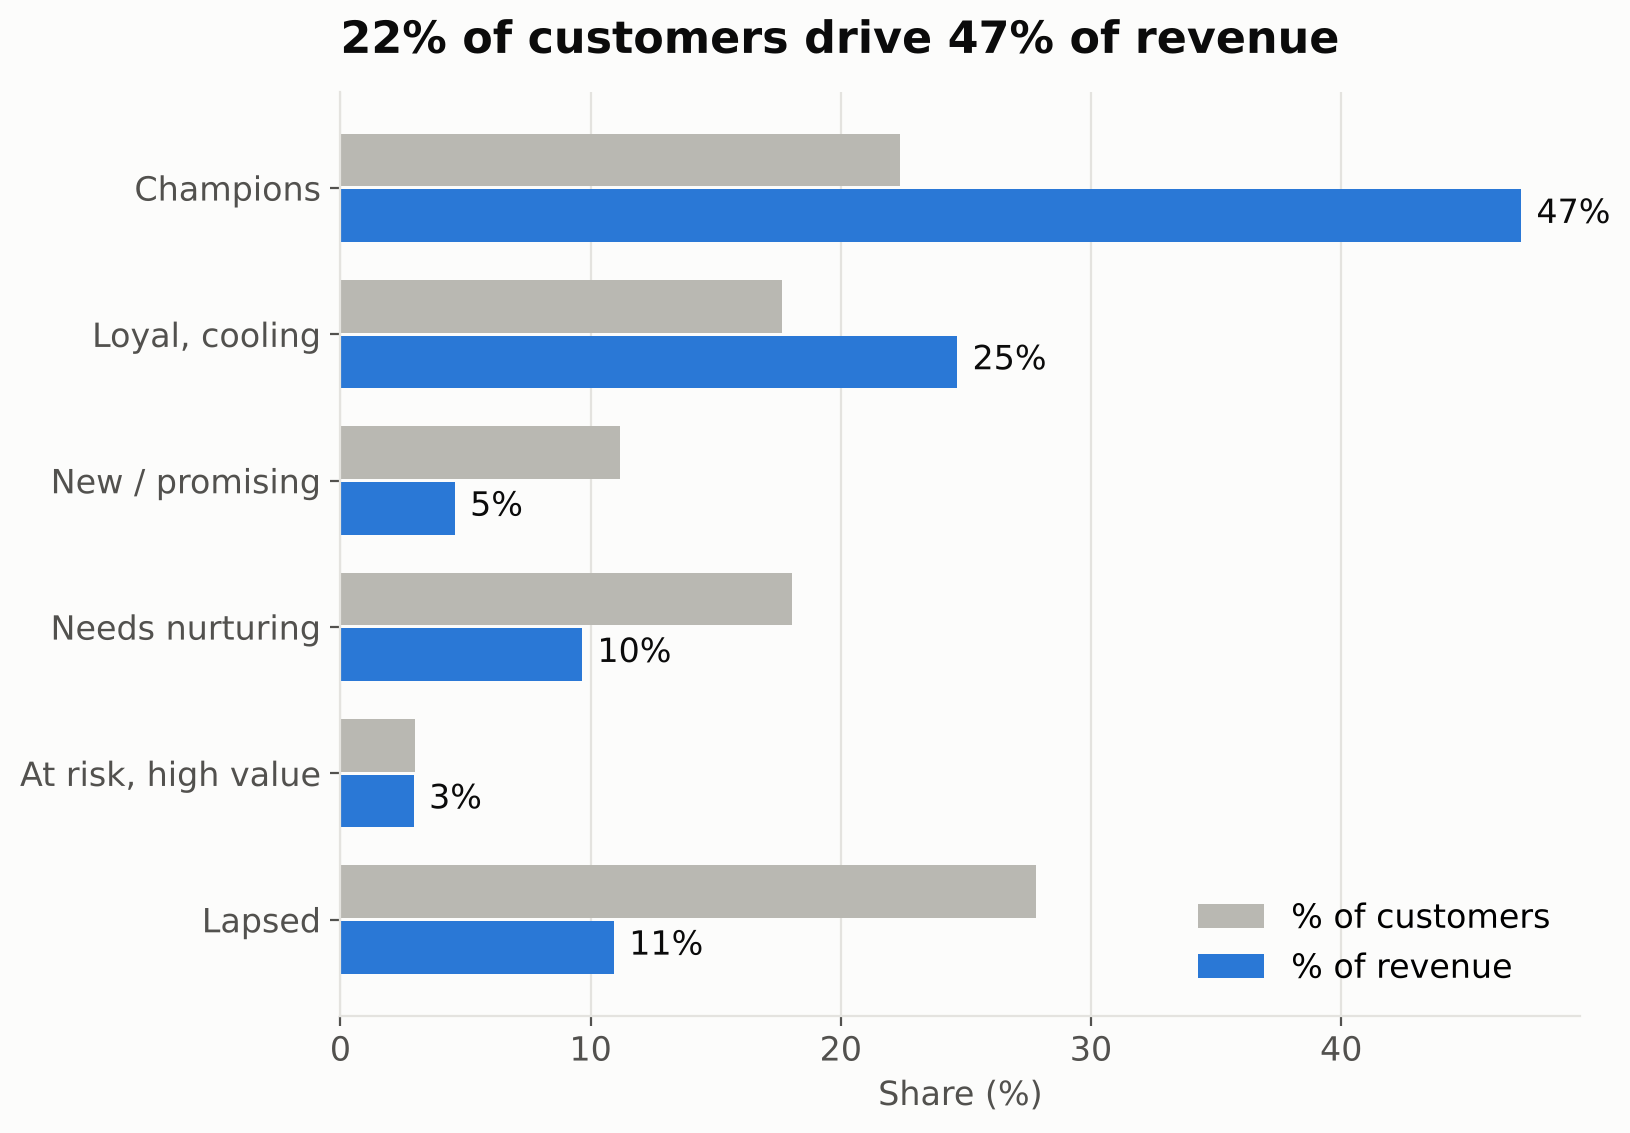

In [9]:
fig,ax=plt.subplots(figsize=(8,6))
y=np.arange(len(order_))[::-1]; h=0.36
ax.barh(y+h/2+0.01,sg['% customers']*100,height=h,color='#b9b8b2',label='% of customers')
ax.barh(y-h/2-0.01,sg['% revenue']*100,height=h,color=PAL[0],label='% of revenue')
for yi,v in zip(y,sg['% revenue']*100): ax.text(v+0.6,yi-h/2,f'{v:.0f}%',va='center',color=INK,fontsize=12)
ax.set_yticks(y,order_); ax.grid(axis='y',visible=False); ax.set_xlabel('Share (%)')
top=sg.loc['Champions']
ax.set_title(f"{top['% customers']:.0%} of customers drive {top['% revenue']:.0%} of revenue",pad=14)
ax.legend(frameon=False,loc='lower right'); save(fig,'04_rfm_segments'); plt.show()

## 5. Customer lifetime value by acquisition channel
12-month revenue per customer for cohorts acquired in the first six months, so every cohort has a full year of history. Pairing this with ROAS changes the story: a channel with a lower first-order return can still win if the customers it brings in keep buying.

             12-mo CLV  Repeat rate
acq_channel                        
Paid Search     271.41         0.61
Paid Social     194.97         0.55
CTV / Video     297.15         0.59
Affiliate       149.73         0.48
Email           358.56         0.67


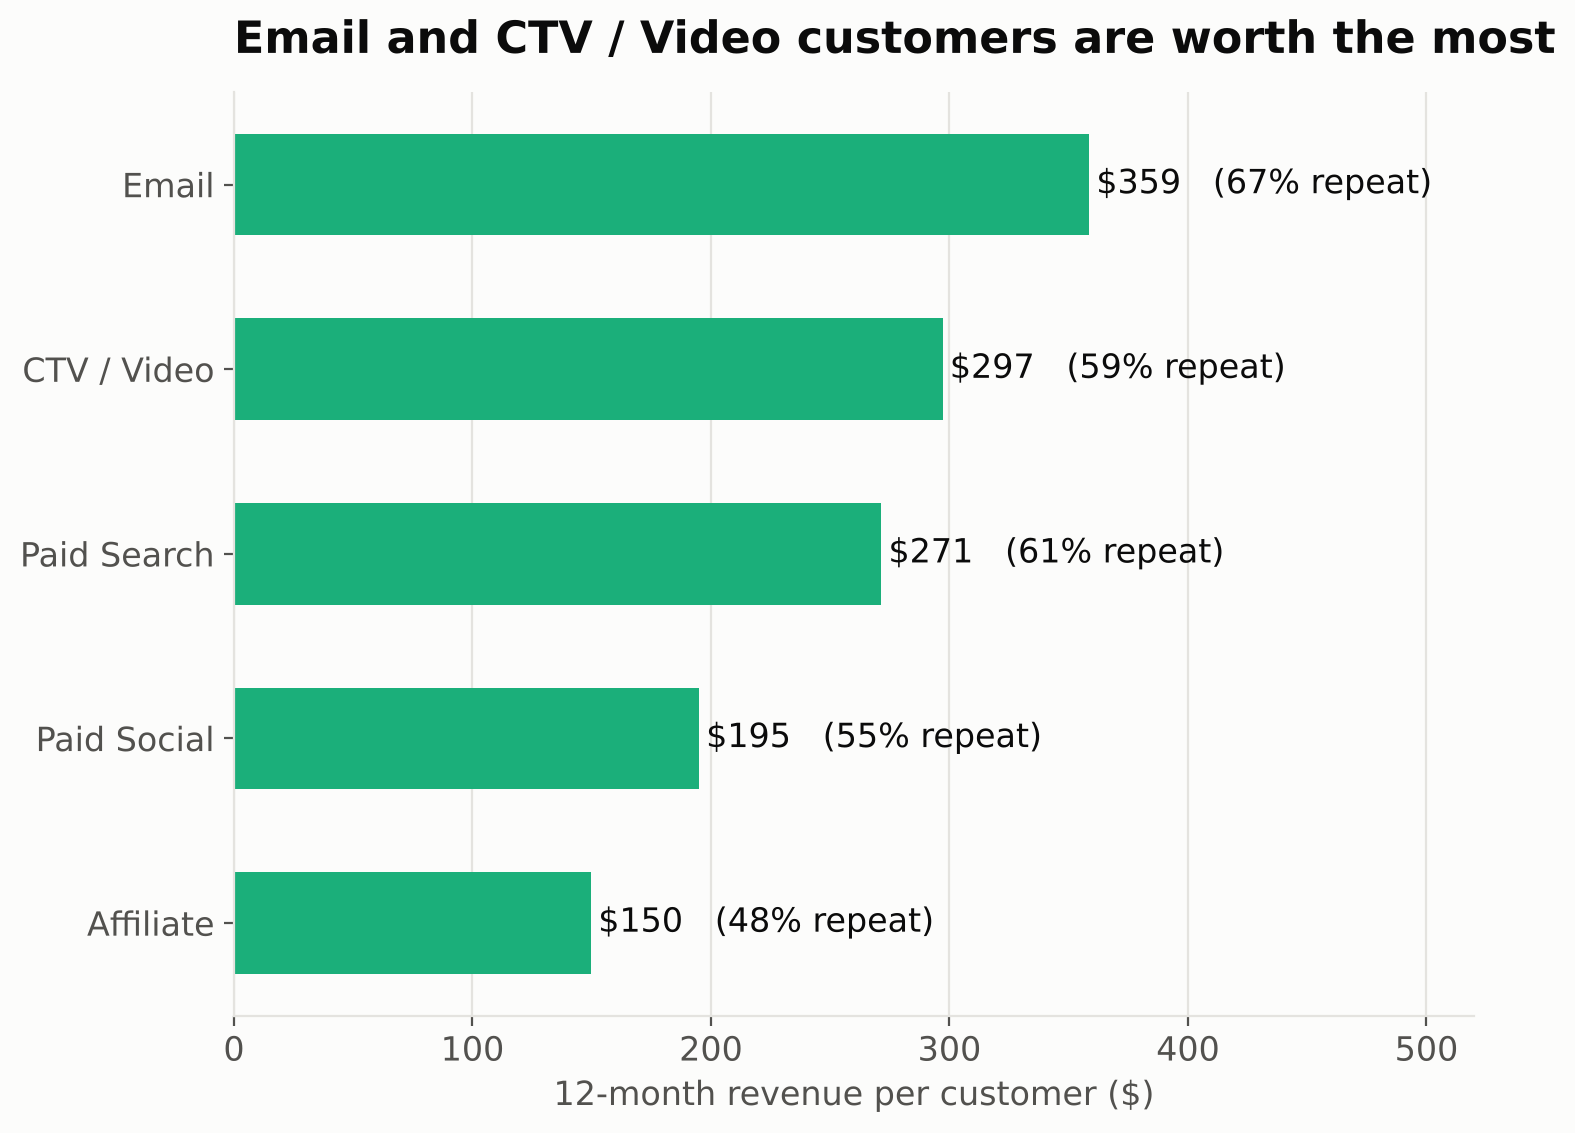

In [10]:
coh=cust[cust.first_day<180]
o=orders.merge(coh,on='customer_id'); o=o[o.day<o.first_day+365]
clv=o.groupby('acq_channel').amount.sum()/coh.groupby('acq_channel').size()
rep=o.groupby(['acq_channel','customer_id']).size().gt(1).groupby('acq_channel').mean()
clv_t=pd.DataFrame({'12-mo CLV':clv,'Repeat rate':rep}).reindex(channels).round(2); print(clv_t)
fig,ax=plt.subplots(figsize=(8,6))
srt=clv_t.sort_values('12-mo CLV'); y=np.arange(len(srt))
ax.barh(y,srt['12-mo CLV'],height=0.55,color=PAL[2])
for yi,(v,rr) in zip(y,zip(srt['12-mo CLV'],srt['Repeat rate'])): ax.text(v+3,yi,f'${v:,.0f}   ({rr:.0%} repeat)',va='center',color=INK,fontsize=12)
ax.set_yticks(y,srt.index); ax.grid(axis='y',visible=False); ax.set_xlabel('12-month revenue per customer ($)')
ax.set_xlim(0,srt['12-mo CLV'].max()*1.45)
t2=srt.index[::-1][:2]; ax.set_title(f'{t2[0]} and {t2[1]} customers are worth the most',pad=14); save(fig,'05_clv_by_channel'); plt.show()

## 6. Who will buy again? Repeat-purchase model
Label: did the customer order in the 90 days after the snapshot? Features use only data available at the snapshot (no leakage). Logistic regression is compared against gradient boosting; if the simpler model holds up, it ships, because it is easier to explain and maintain. The business output is a ranked list: how much of next quarter's repeat buying sits in the top 20% of scored customers.

{'Logistic regression': 0.773, 'Gradient boosting': 0.771} base rate 24.6%
top 20% of scores capture 44% of repeat buyers


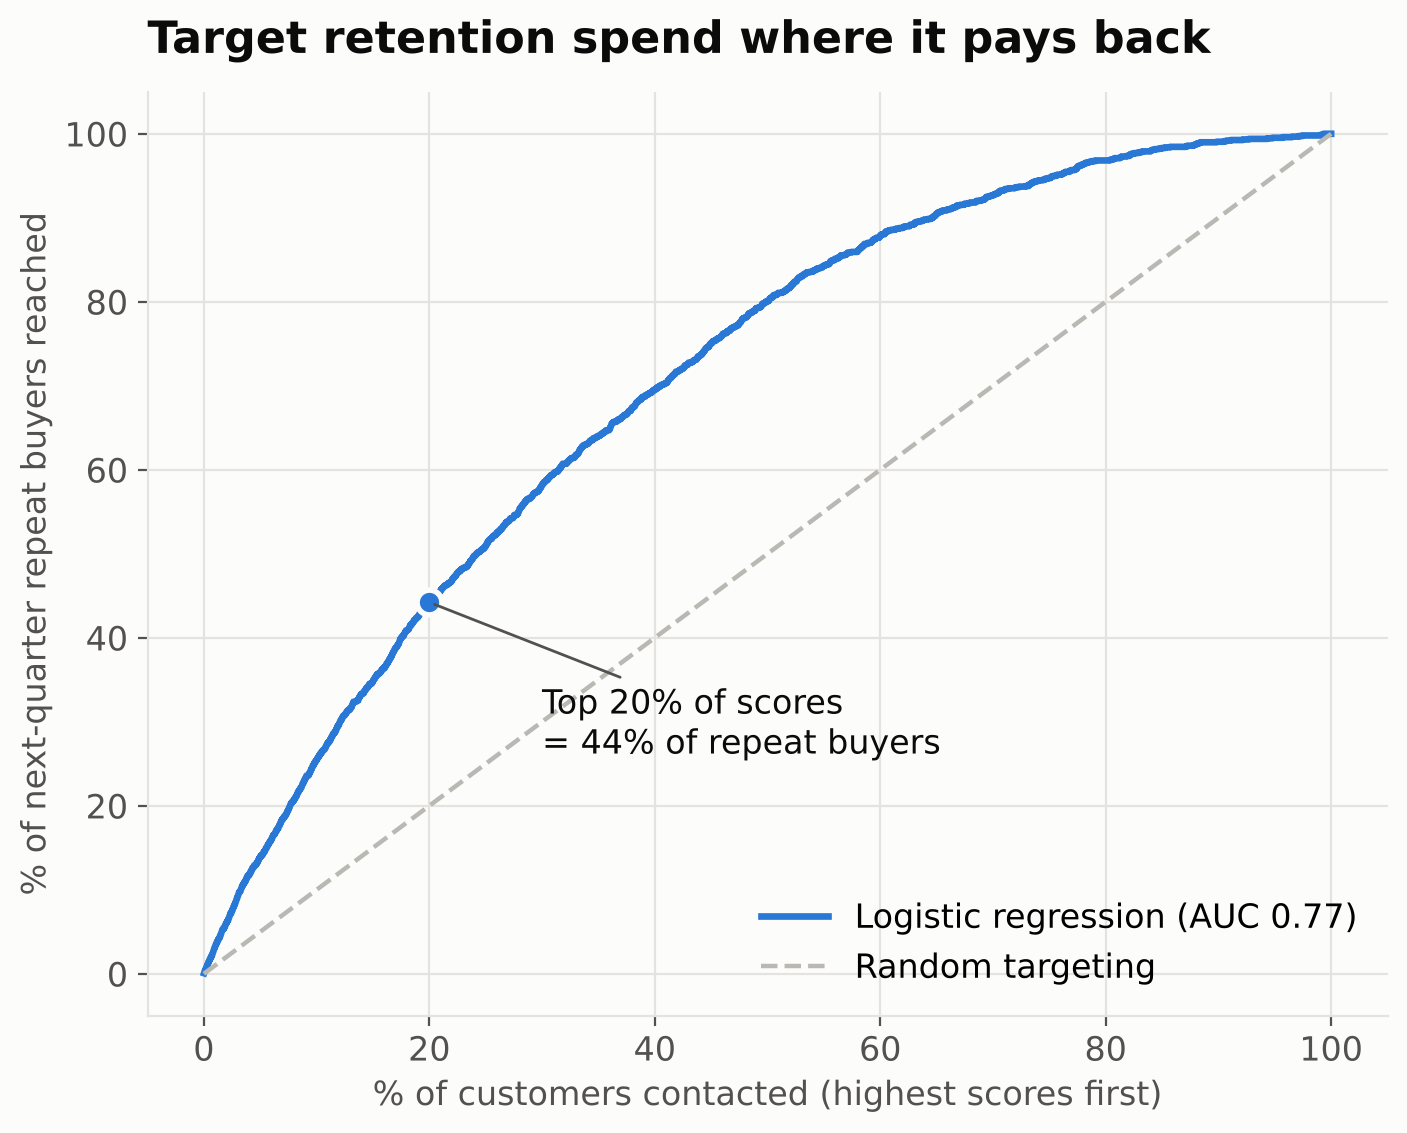

In [11]:
feat=r[['recency','frequency','monetary']].copy()
feat['aov']=feat.monetary/feat.frequency
feat['tenure']=SNAP-cust.set_index('customer_id').loc[feat.index,'first_day']
feat['days_between']=feat.tenure/feat.frequency
feat=feat.join(pd.get_dummies(cust.set_index('customer_id').loc[feat.index,'acq_channel'],prefix='ch',drop_first=True).astype(int))
yb=feat.index.isin(fut[fut.day<SNAP+90].customer_id).astype(int)
Xtr,Xte,ytr,yte=train_test_split(feat,yb,test_size=0.3,random_state=0,stratify=yb)
lr=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)).fit(Xtr,ytr)
gb=HistGradientBoostingClassifier(max_iter=300,learning_rate=0.05,random_state=0).fit(Xtr,ytr)
auc={'Logistic regression':roc_auc_score(yte,lr.predict_proba(Xte)[:,1]),'Gradient boosting':roc_auc_score(yte,gb.predict_proba(Xte)[:,1])}
print({k:round(v,3) for k,v in auc.items()}, f"base rate {yb.mean():.1%}")
sc=lr.predict_proba(Xte)[:,1]; o_=np.argsort(-sc); cum=np.cumsum(yte[o_])/yte.sum(); pct=np.arange(1,len(sc)+1)/len(sc)
top20=cum[int(0.2*len(sc))-1]; print(f"top 20% of scores capture {top20:.0%} of repeat buyers")
fig,ax=plt.subplots(figsize=(8,6))
ax.plot(pct*100,cum*100,color=PAL[0],lw=2.4,label=f"Logistic regression (AUC {auc['Logistic regression']:.2f})")
ax.plot([0,100],[0,100],color='#b9b8b2',lw=1.6,ls='--',label='Random targeting')
ax.scatter([20],[top20*100],s=80,color=PAL[0],zorder=3,edgecolor=SURF,linewidth=2)
ax.annotate(f'Top 20% of scores\n= {top20:.0%} of repeat buyers',(20,top20*100),xytext=(30,top20*100-18),color=INK,fontsize=12,
            arrowprops=dict(arrowstyle='-',color=INK2))
ax.set_xlabel('% of customers contacted (highest scores first)'); ax.set_ylabel('% of next-quarter repeat buyers reached')
ax.set_title('Target retention spend where it pays back',pad=14); ax.legend(frameon=False,loc='lower right')
save(fig,'06_repeat_purchase_gains'); plt.show()

## 7. Recommendations
The numbers below are printed from the analysis above.

In [12]:
delta=alloc.Optimized-alloc.Current; up=delta.idxmax(); dn=delta.idxmin()
print(f"1. Move about ${-delta[dn]*52/1e3:,.0f}K a year out of {dn} ({alloc.Change[dn]:+.0%}) and into {up} ({alloc.Change[up]:+.0%}), and double Email. Same total spend, about {lift:.0%} more media-driven revenue (+${(-opt.fun+neg_rev(cur.values))*52/1e3:,.0f}K a year).")
print(f"2. Judge channels on CLV as well as ROAS. {clv_t['12-mo CLV'].idxmax()} customers are worth ${clv_t['12-mo CLV'].max():.0f} over 12 months vs ${clv_t['12-mo CLV'].min():.0f} for {clv_t['12-mo CLV'].idxmin()}.")
print(f"3. Protect the Champions ({top['% customers']:.0%} of customers, {top['% revenue']:.0%} of revenue) and win back 'At risk, high value' before they lapse.")
print(f"4. Use the repeat-purchase score to focus retention offers: the top 20% of scores reach {top20:.0%} of next quarter's repeat buyers.")
print("5. Before acting on the MMM, validate the biggest shift with a geo holdout test. MMM is a starting point for budget decisions, not a substitute for an experiment.")

1. Move about $546K a year out of Paid Social (-31%) and into Paid Search (+53%), and double Email. Same total spend, about 6% more media-driven revenue (+$549K a year).
2. Judge channels on CLV as well as ROAS. Email customers are worth $359 over 12 months vs $150 for Affiliate.
3. Protect the Champions (22% of customers, 47% of revenue) and win back 'At risk, high value' before they lapse.
4. Use the repeat-purchase score to focus retention offers: the top 20% of scores reach 44% of next quarter's repeat buyers.
5. Before acting on the MMM, validate the biggest shift with a geo holdout test. MMM is a starting point for budget decisions, not a substitute for an experiment.


---
**Methods note.** All data is synthetic and generated in this notebook (seed 42), so every result reproduces exactly. In real engagements the MMM would be fit with Bayesian priors (for example PyMC-Marketing or Meridian), checked with out-of-sample backtests, and calibrated against lift tests.